<a href="https://colab.research.google.com/github/Dhruv0007-J/cars-data-csv/blob/main/Cars_Data_csv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
pd.read_csv('/content/Cars_data.csv')

In [4]:
df = pd.read_csv('/content/Cars_data.csv')

In [ ]:
df.head()

In [6]:
df.dtypes

,0
Make,object
Model,object
Year,int64
Engine Fuel Type,object
Engine HP,float64
Engine Cylinders,float64
Transmission Type,object
Driven_Wheels,object
Number of Doors,float64
Market Category,object


In [7]:
cols_to_drop = [
    "Engine Fuel Type",
    "Market Category",
    "Vehicle Style",
    "Popularity",
    "Number of Doors",
    "Vehicle Size"
]

df = df.drop(columns=cols_to_drop)

In [8]:
rename_cols = {
    "Engine HP": "HP",
    "Engine Cylinders": "Cylinders",
    "Transmission Type": "Transmission",
    "Driven_Wheels": "Drive Mode",
    "MSRP": "Price"
}

df = df.rename(columns=rename_cols)

In [9]:
df.shape

(11914, 10)

In [10]:
df = df.drop_duplicates()

In [11]:
df.shape

(10925, 10)

In [12]:
df.isnull().sum()

,0
Make,0
Model,0
Year,0
HP,69
Cylinders,30
Transmission,0
Drive Mode,0
highway MPG,0
city mpg,0
Price,0


In [13]:
df = df.dropna()

In [14]:
df.describe()

,Year,HP,Cylinders,highway MPG,city mpg,Price
count,10827.000000,10827.000000,10827.000000,10827.000000,10827.000000,1.082700e+04
mean,2010.896370,254.553062,5.691604,26.308119,19.327607,4.249325e+04
std,7.029534,109.841537,1.768551,7.504652,6.643567,6.229451e+04
min,1990.000000,55.000000,0.000000,12.000000,7.000000,2.000000e+03
25%,2007.000000,173.000000,4.000000,22.000000,16.000000,2.197250e+04
50%,2015.000000,240.000000,6.000000,25.000000,18.000000,3.084500e+04
75%,2016.000000,303.000000,6.000000,30.000000,22.000000,4.330000e+04
max,2017.000000,1001.000000,16.000000,354.000000,137.000000,2.065902e+06


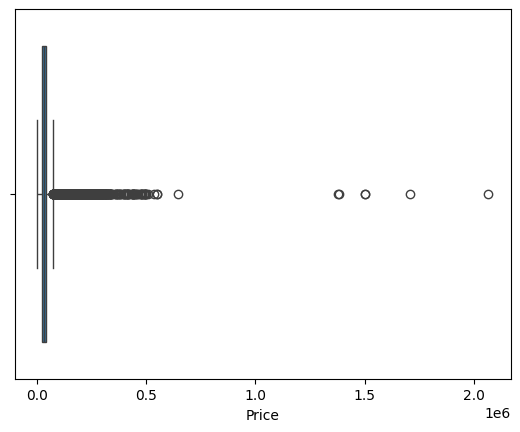

In [20]:
sns.boxplot(x=df["Price"])
plt.show()

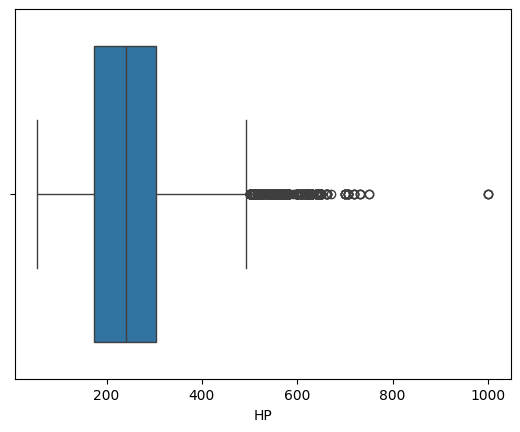

In [22]:
sns.boxplot(x=df["HP"])
plt.show()

In [23]:
l = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

In [24]:
["Year", "HP", "Cylinders", "Price"]

['Year', 'HP', 'Cylinders', 'Price']

In [25]:
Q1 = df["Price"].quantile(0.25)
Q3 = df["Price"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df2 = df[
    (df["Price"] >= lower_limit) &
    (df["Price"] <= upper_limit)
]

In [26]:
print(df.shape)
print(df2.shape)

(10827, 10)
(9891, 10)


In [27]:
for i in df.columns:
    print(i)
    print(df[i].value_counts())

Make
Make
Chevrolet        1043
Ford              798
Toyota            651
Volkswagen        563
Nissan            540
Dodge             513
GMC               475
Honda             429
Cadillac          396
Mazda             392
Mercedes-Benz     340
Suzuki            338
Infiniti          326
BMW               324
Audi              320
Hyundai           254
Acura             246
Volvo             241
Subaru            229
Kia               219
Mitsubishi        202
Lexus             201
Chrysler          185
Buick             184
Pontiac           163
Lincoln           152
Porsche           134
Land Rover        126
Oldsmobile        111
Saab              101
Aston Martin       91
Bentley            74
Ferrari            69
Plymouth           62
Scion              60
FIAT               58
Maserati           55
Lamborghini        52
Rolls-Royce        31
Lotus              28
HUMMER             17
Maybach            16
Alfa Romeo          5
McLaren             5
Genesis             3


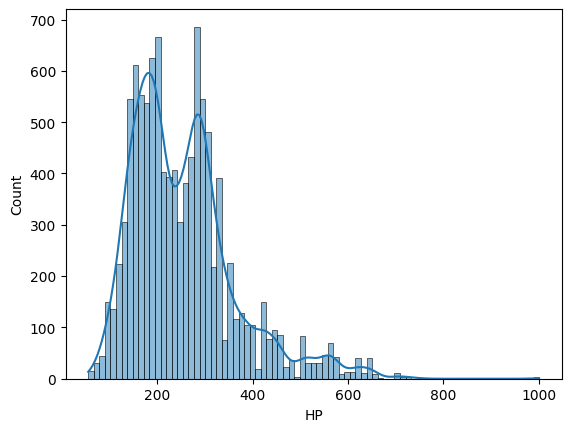

In [28]:
sns.histplot(df["HP"], kde=True)
plt.show()

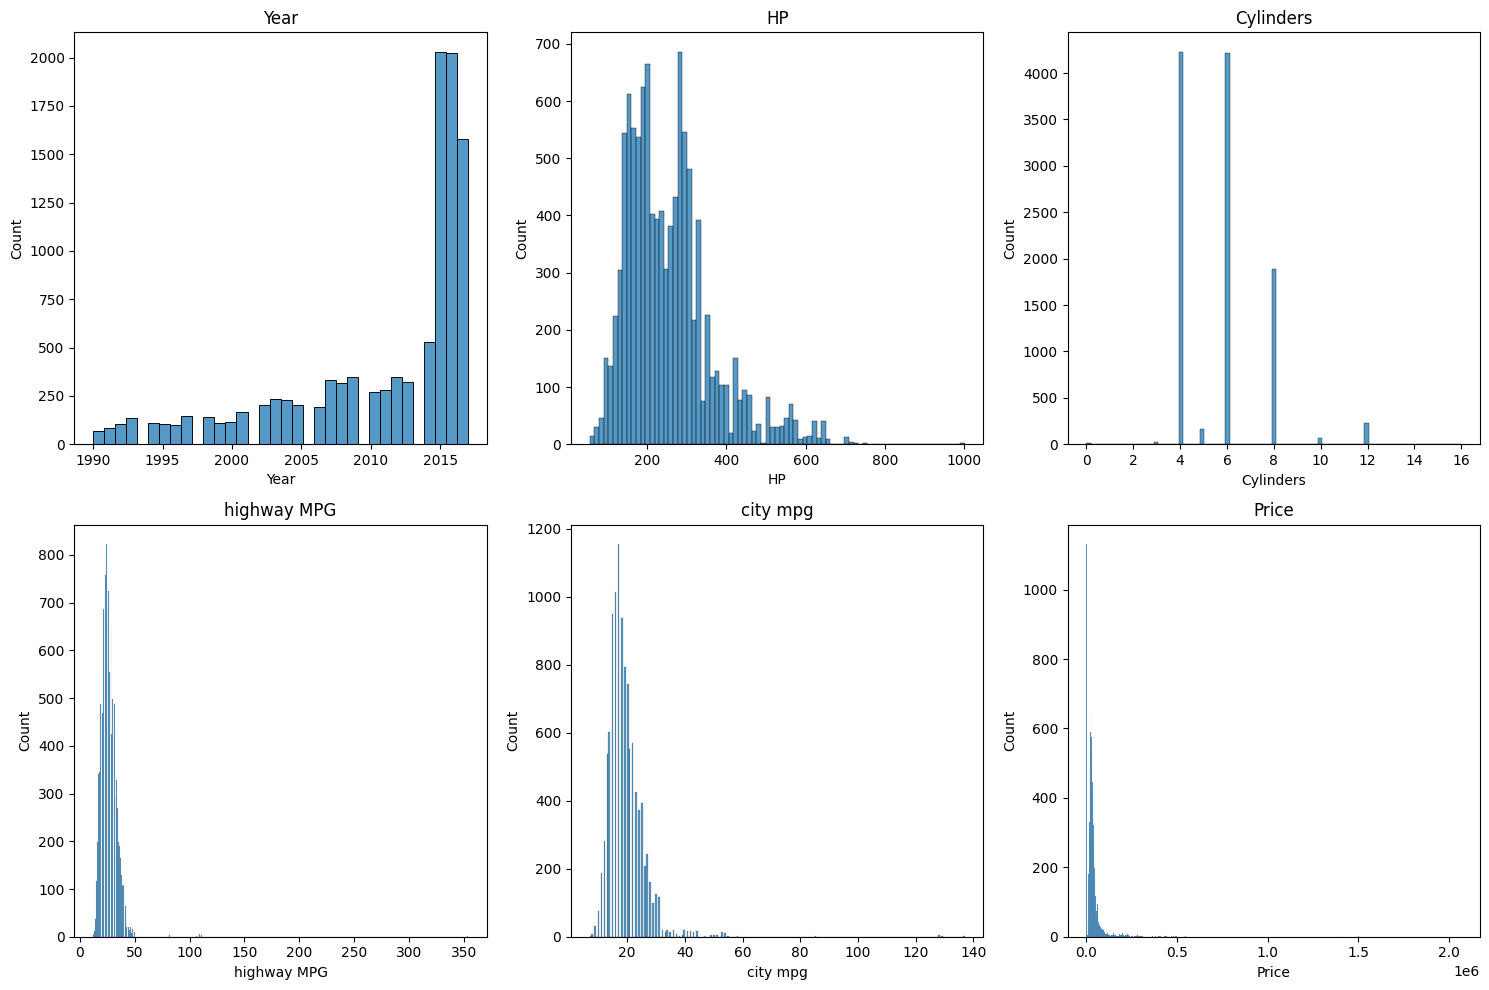

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, ax in zip(l, axes.flatten()):
    sns.histplot(df[i], ax=ax)
    ax.set_title(i)

plt.tight_layout()
plt.show()

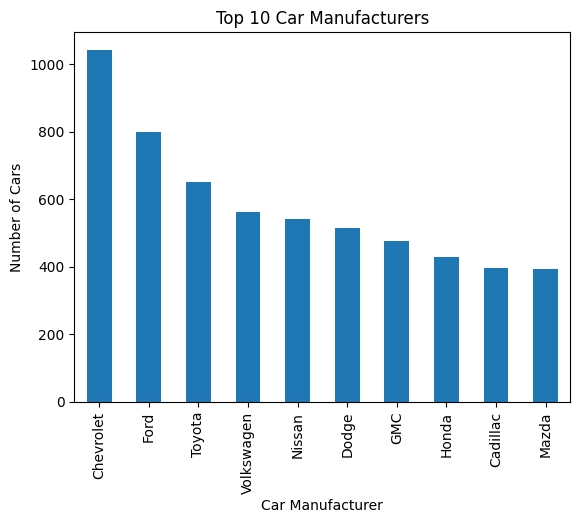

In [30]:
df["Make"].value_counts().nlargest(10).plot(kind="bar")

plt.title("Top 10 Car Manufacturers")
plt.xlabel("Car Manufacturer")
plt.ylabel("Number of Cars")

plt.show()

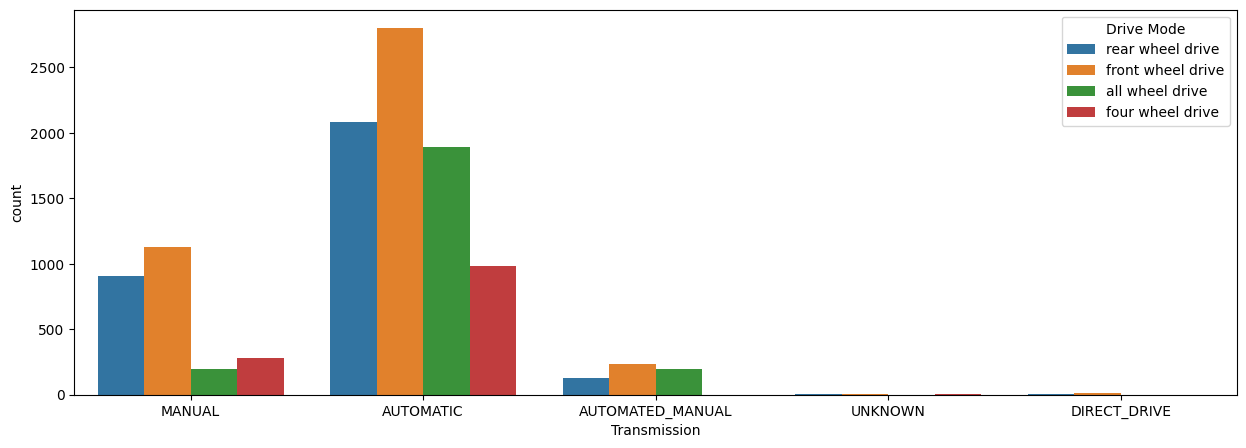

In [31]:
plt.figure(figsize=(15, 5))

sns.countplot(
    data=df,
    x="Transmission",
    hue="Drive Mode"
)

plt.show()

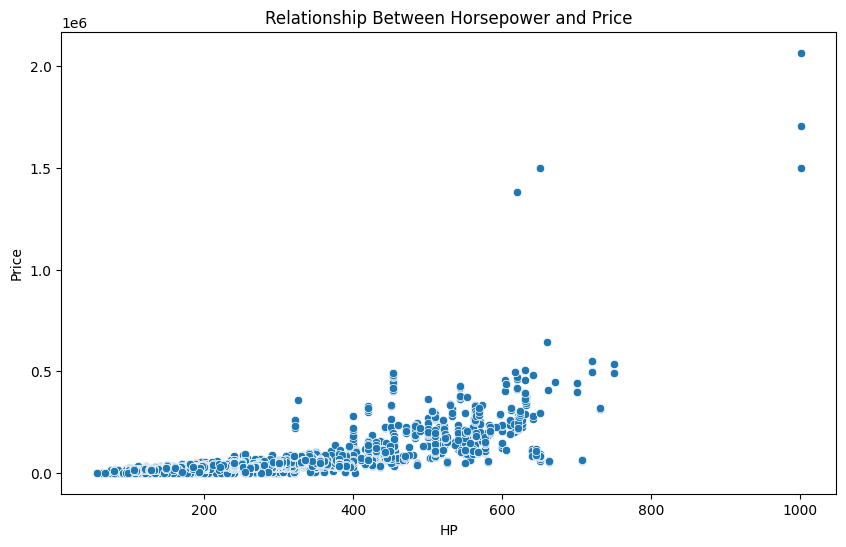

In [32]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="HP",
    y="Price"
)

plt.title("Relationship Between Horsepower and Price")
plt.show()

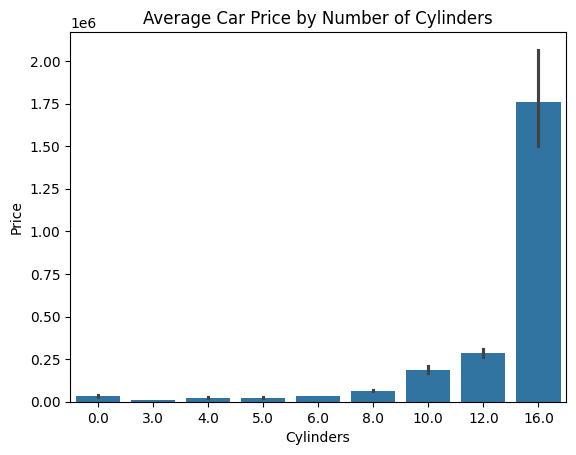

In [33]:
sns.barplot(
    data=df,
    x="Cylinders",
    y="Price"
)

plt.title("Average Car Price by Number of Cylinders")
plt.show()

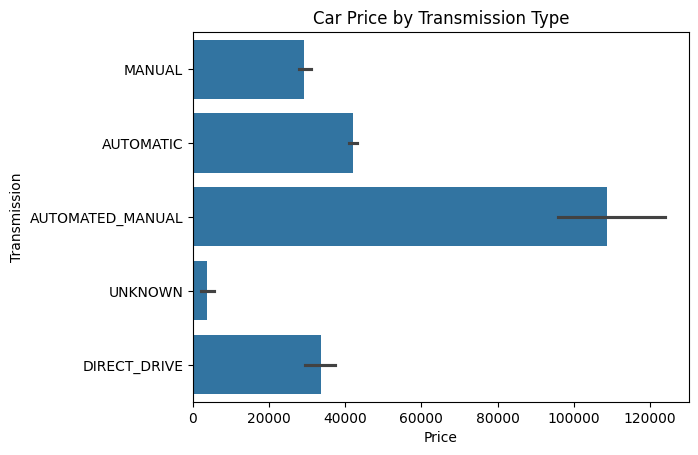

In [34]:
sns.barplot(
    data=df,
    x="Price",
    y="Transmission"
)

plt.title("Car Price by Transmission Type")
plt.show()

In [35]:
corr = df.select_dtypes(
    include=["int64", "float64"]
).corr()

print(corr)

                 Year        HP  Cylinders  highway MPG  city mpg     Price
Year         1.000000  0.314971  -0.050598     0.284237  0.234135  0.196789
HP           0.314971  1.000000   0.788007    -0.420281 -0.473551  0.659835
Cylinders   -0.050598  0.788007   1.000000    -0.611576 -0.632407  0.554740
highway MPG  0.284237 -0.420281  -0.611576     1.000000  0.841229 -0.209150
city mpg     0.234135 -0.473551  -0.632407     0.841229  1.000000 -0.234050
Price        0.196789  0.659835   0.554740    -0.209150 -0.234050  1.000000


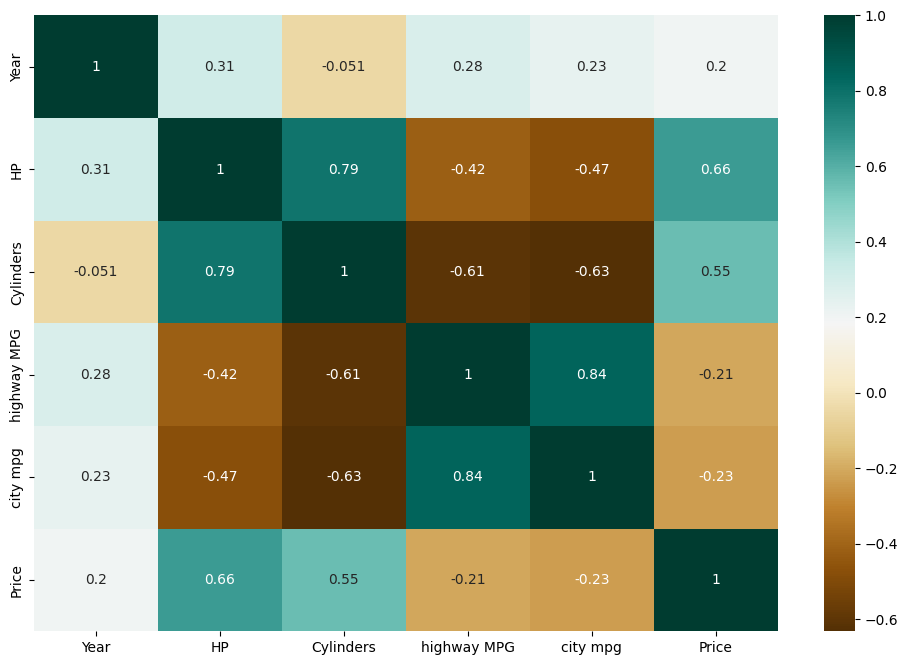

In [36]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    cmap="BrBG",
    annot=True
)

plt.show()